# Building-type ground truth + AlphaEarth embeddings

**Goal.** Build a multi-class labeled dataset linking Overture building-use labels to
**AlphaEarth Satellite Embedding V1** (64-D) for downstream building-type classification
and embedding-space analysis.

**Labels.** Phase 1 study rollup of Overture `class` (OSM-derived only). Unlabeled
footprints are excluded — never treated as negatives.

**Features.** 2024 annual embeddings at building centroids (`Reducer.first`, scale=10 m).

**Outputs** (`outputs/building_gt/`):

| File | Role |
|---|---|
| `building_labels.parquet` | Labels + sample lon/lat |
| `building_embeddings.parquet` | `id` + `A00`–`A63` cache |
| `building_gt.parquet` | Inner join — analysis-ready GT |
| `qa_*.png` / `qa_*.csv` | Spatial alignment verification |

**Requires.** DuckDB + network for Overture S3. Earth Engine (`EE_PROJECT`) for embeddings
and RGB overlay. Label scatter / join bars run without EE if embeddings are already cached.


## Setup

```bash
pip install -r requirements.txt
earthengine authenticate --auth_mode=notebook
export EE_PROJECT=your-ee-cloud-project-id
```


In [1]:
from __future__ import annotations

import io
import json
import os
import time
import warnings
import urllib.request as urlreq
from pathlib import Path

import duckdb
import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent
OUT_DIR = ROOT / "outputs" / "building_gt"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
EMBED_YEAR = 2024
SAMPLE_METHOD = "centroid_first"
N_PER_CLASS = 100  # target samples per study label per region (take all if fewer)
EE_BATCH = 400
RANDOM_STATE = 42
PIXEL_DECIMALS = 5  # ~1 m lon at equator; ~10 m scale diagnostic

EE_PROJECT = os.environ.get("EE_PROJECT", "ee-kedarvaidya0504")

ROLLUP = {
    "single_family_like": ["house", "detached", "bungalow", "semi", "semidetached_house"],
    "terrace_ambiguous": ["terrace"],
    "multi_family": ["apartments", "dormitory"],
    "residential_generic": ["residential"],
    "education": ["school", "kindergarten", "college", "university"],
    "hospital": ["hospital"],
    "commercial_office": ["office", "commercial", "retail", "hotel", "supermarket"],
    "industrial": ["industrial", "warehouse", "factory"],
}

print("ROOT:", ROOT)
print("Outputs:", OUT_DIR)
print("EE_PROJECT:", EE_PROJECT)


/home/kv133/Alpha-Earth-Embeddings-Research/.venv/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
Outputs: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt
EE_PROJECT: ee-kedarvaidya0504


**Result.** Environment ready. Paths point at `outputs/building_gt/`; Earth Engine project is `ee-kedarvaidya0504`. (Python 3.10 warning from Google libs is harmless for now.)

## US regions

Same compact metro AOIs as the residential trial notebook. Dense OSM cores keep
multi-class `class` labels usable; AOIs stay small for cheap Overture + EE queries.


In [2]:
US_REGIONS: dict[str, tuple[float, float, float, float]] = {
    # name: (xmin, ymin, xmax, ymax)  — lon/lat
    "Boston_NE": (-71.20, 42.28, -70.95, 42.42),
    "NYC_NE": (-74.05, 40.68, -73.90, 40.82),
    "Chicago_MW": (-87.75, 41.80, -87.55, 41.95),
    "Atlanta_SE": (-84.45, 33.70, -84.30, 33.85),
    "Houston_S": (-95.50, 29.70, -95.25, 29.85),
    "Denver_W": (-105.05, 39.68, -104.90, 39.80),
    "Phoenix_SW": (-112.15, 33.40, -111.95, 33.55),
    "Seattle_NW": (-122.40, 47.55, -122.25, 47.68),
    "LA_W": (-118.35, 34.00, -118.20, 34.12),
}


def region_centroid(bbox: tuple[float, float, float, float]) -> tuple[float, float]:
    xmin, ymin, xmax, ymax = bbox
    return (0.5 * (xmin + xmax), 0.5 * (ymin + ymax))


region_meta = pd.DataFrame(
    [
        {
            "region": name,
            "lon": region_centroid(b)[0],
            "lat": region_centroid(b)[1],
            "xmin": b[0],
            "ymin": b[1],
            "xmax": b[2],
            "ymax": b[3],
        }
        for name, b in US_REGIONS.items()
    ]
)
region_meta


,region,lon,lat,xmin,ymin,xmax,ymax
0,Boston_NE,-71.075,42.350,-71.200,42.280,-70.950,42.420
1,NYC_NE,-73.975,40.750,-74.050,40.680,-73.900,40.820
2,Chicago_MW,-87.650,41.875,-87.750,41.800,-87.550,41.950
3,Atlanta_SE,-84.375,33.775,-84.450,33.700,-84.300,33.850
4,Houston_S,-95.375,29.775,-95.500,29.700,-95.250,29.850
5,Denver_W,-104.975,39.740,-105.050,39.680,-104.900,39.800
6,Phoenix_SW,-112.050,33.475,-112.150,33.400,-111.950,33.550
7,Seattle_NW,-122.325,47.615,-122.400,47.550,-122.250,47.680
8,LA_W,-118.275,34.060,-118.350,34.000,-118.200,34.120


**Result.** Defined **9 US metro boxes** (Boston → LA). Small downtown-ish AOIs keep queries fast and OSM class tags denser.

## 1. Sample multi-class Overture labels

Map Overture `class` → study rollup (`label`). Stratified sample of up to
`N_PER_CLASS` buildings **per label per region**. Buildings whose `class` is outside
the rollup (or null) are excluded.


In [3]:
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("SET s3_region='us-west-2';")
con.execute("SET s3_access_key_id='';")
con.execute("SET s3_secret_access_key='';")
print("DuckDB ready ·", RELEASE)

# Invert rollup for SQL CASE
_class_to_label = {c: lab for lab, members in ROLLUP.items() for c in members}
_case_parts = "\n".join(
    f"      WHEN class = '{c}' THEN '{lab}'"
    for c, lab in sorted(_class_to_label.items())
)


def sample_region(name: str, bbox: tuple[float, float, float, float], n_per_class: int) -> pd.DataFrame:
    xmin, ymin, xmax, ymax = bbox
    sql = f"""
    WITH b AS (
      SELECT
        id,
        subtype,
        class,
        ST_X(ST_Centroid(geometry)) AS lon,
        ST_Y(ST_Centroid(geometry)) AS lat
      FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
      WHERE bbox.xmin BETWEEN {xmin} AND {xmax}
        AND bbox.ymin BETWEEN {ymin} AND {ymax}
        AND class IS NOT NULL
        AND geometry IS NOT NULL
    ),
    labeled AS (
      SELECT
        id, subtype, class, lon, lat,
        CASE
{_case_parts}
          ELSE NULL
        END AS label
      FROM b
      WHERE lon BETWEEN {xmin} AND {xmax}
        AND lat BETWEEN {ymin} AND {ymax}
    ),
    mapped AS (
      SELECT * FROM labeled WHERE label IS NOT NULL
    ),
    sampled AS (
      SELECT * FROM (
        SELECT *, row_number() OVER (PARTITION BY label ORDER BY hash(id)) AS rn
        FROM mapped
      ) t
      WHERE rn <= {n_per_class}
    )
    SELECT
      id,
      '{name}' AS region,
      subtype,
      class,
      label,
      lon,
      lat,
      {EMBED_YEAR} AS embed_year,
      '{SAMPLE_METHOD}' AS sample_method
    FROM sampled
    """
    return con.execute(sql).df()


cache_labels = OUT_DIR / "building_labels.parquet"
if cache_labels.exists():
    labels = pd.read_parquet(cache_labels)
    print("Loaded cached labels:", cache_labels)
else:
    frames = []
    for name, bbox in US_REGIONS.items():
        print(f"Sampling · {name} ...", flush=True)
        frames.append(sample_region(name, bbox, N_PER_CLASS))
    labels = pd.concat(frames, ignore_index=True)
    labels["id"] = labels["id"].astype(str)
    labels.to_parquet(cache_labels, index=False)
    print("Wrote", cache_labels)

print("n =", len(labels))
print(labels.groupby("label").size().sort_values(ascending=False))
counts = (
    labels.groupby(["region", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=list(ROLLUP.keys()), fill_value=0)
)
counts


DuckDB ready · 2026-08-19.0
Sampling · Boston_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · NYC_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · Chicago_MW ...


...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · LA_W ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/building_labels.parquet
n = 6822
label
commercial_office      900
education              900
residential_generic    900
multi_family           900
single_family_like     900
industrial             884
terrace_ambiguous      835
hospital               603
dtype: int64


label,single_family_like,terrace_ambiguous,multi_family,residential_generic,education,hospital,commercial_office,industrial
region,,,,,,,,
Atlanta_SE,100,100,100,100,100,34,100,84
Boston_NE,100,100,100,100,100,96,100,100
Chicago_MW,100,100,100,100,100,79,100,100
Denver_W,100,100,100,100,100,37,100,100
Houston_S,100,100,100,100,100,56,100,100
LA_W,100,35,100,100,100,100,100,100
NYC_NE,100,100,100,100,100,84,100,100
Phoenix_SW,100,100,100,100,100,60,100,100
Seattle_NW,100,100,100,100,100,57,100,100


**Result.** Sampled **6,822** labeled buildings across 9 US metros (up to ~100 per class per city). Most classes are full; hospitals and some terraces/industrial are thinner where OSM tags are scarce (e.g. LA terraces = 35, Atlanta hospitals = 34).

## 2. Extract AlphaEarth embeddings & write GT

Point-in-pixel sample of the annual mosaic at each building centroid
(`ee.Geometry.Point` → `reduceRegions` → `Reducer.first`, `scale=10`).

Join on Overture `id` (not coordinates). Drop rows with any null band before writing
`building_gt.parquet`.


In [4]:
def init_ee(project: str) -> None:
    if not project or project == "YOUR_EE_PROJECT_ID":
        raise ValueError(
            "Set EE_PROJECT to your Earth Engine Cloud project id "
            "(cell above or export EE_PROJECT=...)."
        )
    try:
        ee.Initialize(project=project)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=project)
    print("Earth Engine initialized · project =", project)


def annual_embedding_image(year: int) -> ee.Image:
    return (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
        .mosaic()
    )


BANDS = [f"A{i:02d}" for i in range(64)]


def extract_embeddings(df: pd.DataFrame, year: int = EMBED_YEAR, batch_size: int = EE_BATCH) -> pd.DataFrame:
    """Sample 64-D embeddings at lon/lat; returns id + A00..A63 + metadata."""
    init_ee(EE_PROJECT)
    img = annual_embedding_image(year)
    rows: list[dict] = []
    n = len(df)
    for start in range(0, n, batch_size):
        batch = df.iloc[start : start + batch_size]
        feats = []
        for _, r in batch.iterrows():
            feats.append(
                ee.Feature(
                    ee.Geometry.Point([float(r["lon"]), float(r["lat"])]),
                    {"row_id": str(r["id"]), "region": r["region"]},
                )
            )
        fc = ee.FeatureCollection(feats)
        sampled = img.reduceRegions(
            collection=fc,
            reducer=ee.Reducer.first(),
            scale=10,
            tileScale=4,
        )
        print(f"EE reduceRegions · {start}:{start + len(batch)} / {n}", flush=True)
        info = sampled.getInfo()
        for f in info["features"]:
            props = f["properties"]
            row = {
                "id": props.get("row_id"),
                "region": props.get("region"),
                "embed_year": year,
                "sample_method": SAMPLE_METHOD,
            }
            for b in BANDS:
                row[b] = props.get(b)
            rows.append(row)
        time.sleep(0.5)
    out = pd.DataFrame(rows)
    return out


n_labels_before = len(labels)
cache_emb = OUT_DIR / "building_embeddings.parquet"

if cache_emb.exists():
    embeddings = pd.read_parquet(cache_emb)
    embeddings = embeddings.dropna(subset=BANDS).reset_index(drop=True)
    print("Loaded cached embeddings:", cache_emb, "· n =", len(embeddings))
else:
    raw = extract_embeddings(labels)
    n_raw = len(raw)
    embeddings = raw.dropna(subset=BANDS).reset_index(drop=True)
    n_dropped_null = n_raw - len(embeddings)
    embeddings.to_parquet(cache_emb, index=False)
    print("Wrote", cache_emb, "· n =", len(embeddings), "· dropped_null_bands =", n_dropped_null)

embeddings["id"] = embeddings["id"].astype(str)
labels["id"] = labels["id"].astype(str)

gt = labels.merge(embeddings[["id"] + BANDS], on="id", how="inner")
# Keep a single copy of sampling metadata from the label table
gt["embed_year"] = EMBED_YEAR
gt["sample_method"] = SAMPLE_METHOD

assert gt[BANDS].notna().all().all(), "Joined GT still has null embedding bands"
assert len(BANDS) == 64

gt_path = OUT_DIR / "building_gt.parquet"
gt.to_parquet(gt_path, index=False)
print("Wrote", gt_path, "· n =", len(gt))
print(
    "Join · labels=",
    len(labels),
    "embeddings=",
    len(embeddings),
    "joined=",
    len(gt),
    "dropped=",
    len(labels) - len(gt),
)
print(gt.groupby(["region", "label"]).size().unstack(fill_value=0).reindex(columns=list(ROLLUP.keys()), fill_value=0))


Earth Engine initialized · project = ee-kedarvaidya0504
EE reduceRegions · 0:400 / 6822
EE reduceRegions · 400:800 / 6822
EE reduceRegions · 800:1200 / 6822
EE reduceRegions · 1200:1600 / 6822
EE reduceRegions · 1600:2000 / 6822
EE reduceRegions · 2000:2400 / 6822
EE reduceRegions · 2400:2800 / 6822
EE reduceRegions · 2800:3200 / 6822
EE reduceRegions · 3200:3600 / 6822
EE reduceRegions · 3600:4000 / 6822
EE reduceRegions · 4000:4400 / 6822
EE reduceRegions · 4400:4800 / 6822
EE reduceRegions · 4800:5200 / 6822
EE reduceRegions · 5200:5600 / 6822
EE reduceRegions · 5600:6000 / 6822
EE reduceRegions · 6000:6400 / 6822
EE reduceRegions · 6400:6800 / 6822
EE reduceRegions · 6800:6822 / 6822
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/building_embeddings.parquet · n = 6822 · dropped_null_bands = 0
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/building_gt.parquet · n = 6822
Join · labels= 6822 embeddings= 6822 joined= 6822 droppe

**Result.** Pulled AlphaEarth 64-D vectors for all **6,822** buildings via Earth Engine. **0** null embeddings — every label got a feature vector. Saved `building_gt.parquet`.

## 3. Numeric QA

- Centroids finite and inside their region bbox
- No null embedding bands in the joined table
- Shared-pixel collision rate (~10 m rounding)
- Per-region join integrity counts


In [5]:
# --- numeric spatial / schema QA ---
region_bbox = {r["region"]: (r["xmin"], r["ymin"], r["xmax"], r["ymax"]) for _, r in region_meta.iterrows()}

bad_coords = []
for _, row in gt.iterrows():
    xmin, ymin, xmax, ymax = region_bbox[row["region"]]
    if not (np.isfinite(row["lon"]) and np.isfinite(row["lat"])):
        bad_coords.append(row["id"])
    elif not (xmin <= row["lon"] <= xmax and ymin <= row["lat"] <= ymax):
        bad_coords.append(row["id"])

assert not bad_coords, f"{len(bad_coords)} points outside region bbox or non-finite"

gt["pixel_key"] = (
    gt["lon"].round(PIXEL_DECIMALS).astype(str) + "," + gt["lat"].round(PIXEL_DECIMALS).astype(str)
)
shared = gt.groupby("pixel_key").size()
n_collision_pixels = int((shared > 1).sum())
n_collision_buildings = int(shared[shared > 1].sum())
print(f"Shared-pixel (~10 m) collisions: {n_collision_pixels} pixels · {n_collision_buildings} buildings")

# Join integrity per region
integrity_rows = []
for region in sorted(US_REGIONS):
    n_lab = int((labels["region"] == region).sum())
    n_emb = int((embeddings["region"] == region).sum())
    n_gt = int((gt["region"] == region).sum())
    integrity_rows.append(
        {
            "region": region,
            "n_labels": n_lab,
            "n_embeddings": n_emb,
            "n_joined": n_gt,
            "n_dropped": n_lab - n_gt,
        }
    )
integrity = pd.DataFrame(integrity_rows)
integrity_path = OUT_DIR / "join_integrity.csv"
integrity.to_csv(integrity_path, index=False)
print("Wrote", integrity_path)
integrity


Shared-pixel (~10 m) collisions: 0 pixels · 0 buildings
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/join_integrity.csv


,region,n_labels,n_embeddings,n_joined,n_dropped
0,Atlanta_SE,718,718,718,0
1,Boston_NE,796,796,796,0
2,Chicago_MW,779,779,779,0
3,Denver_W,737,737,737,0
4,Houston_S,756,756,756,0
5,LA_W,735,735,735,0
6,NYC_NE,784,784,784,0
7,Phoenix_SW,760,760,760,0
8,Seattle_NW,757,757,757,0


**Result.** QA passed: every region kept all its samples (0 dropped). No two buildings share the same 10 m embedding pixel globally (**0 collisions**). Join is clean.

## 4. Spatial alignment visuals

Figures for verifying that GT points and embeddings refer to the same places.


### 4a. AOI scatter by label (no EE)


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_aoi_scatter_by_label.png


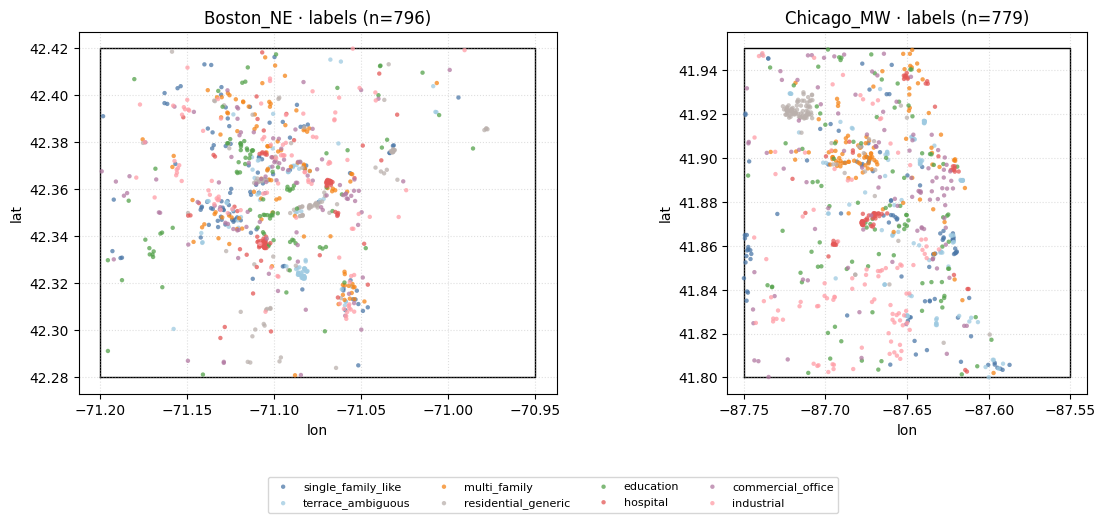

In [6]:
EXAMPLE_REGIONS = ["Boston_NE", "Chicago_MW"]
label_colors = {
    "single_family_like": "#4C78A8",
    "terrace_ambiguous": "#9ecae1",
    "multi_family": "#F58518",
    "residential_generic": "#bab0ac",
    "education": "#54A24B",
    "hospital": "#E45756",
    "commercial_office": "#B279A2",
    "industrial": "#FF9DA6",
}

fig, axes = plt.subplots(1, len(EXAMPLE_REGIONS), figsize=(12, 5.2), sharey=False)
if len(EXAMPLE_REGIONS) == 1:
    axes = [axes]

for ax, region in zip(axes, EXAMPLE_REGIONS):
    sub = labels[labels["region"] == region]
    xmin, ymin, xmax, ymax = US_REGIONS[region]
    ax.plot(
        [xmin, xmax, xmax, xmin, xmin],
        [ymin, ymin, ymax, ymax, ymin],
        color="k",
        lw=1.0,
        zorder=1,
    )
    for lab, color in label_colors.items():
        pts = sub[sub["label"] == lab]
        if pts.empty:
            continue
        ax.scatter(
            pts["lon"],
            pts["lat"],
            s=10,
            c=color,
            label=lab,
            alpha=0.75,
            edgecolors="none",
            zorder=2,
        )
    ax.set_title(f"{region} · labels (n={len(sub)})")
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    ax.set_aspect(1.0 / np.cos(np.deg2rad(0.5 * (ymin + ymax))))
    ax.grid(True, linestyle=":", alpha=0.4)

handles, labs_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labs_, loc="lower center", ncol=4, fontsize=8, frameon=True)
fig.tight_layout(rect=(0, 0.12, 1, 1))
scatter_path = OUT_DIR / "qa_aoi_scatter_by_label.png"
fig.savefig(scatter_path, dpi=150)
print("Saved", scatter_path)
plt.show()


**Result.** Map of sampled buildings in Boston and Chicago, colored by building type. Points fall inside the AOIs and mix of types looks spatially sensible (not one clump of a single class).

### 4b. Join integrity bars


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_join_integrity_bars.png


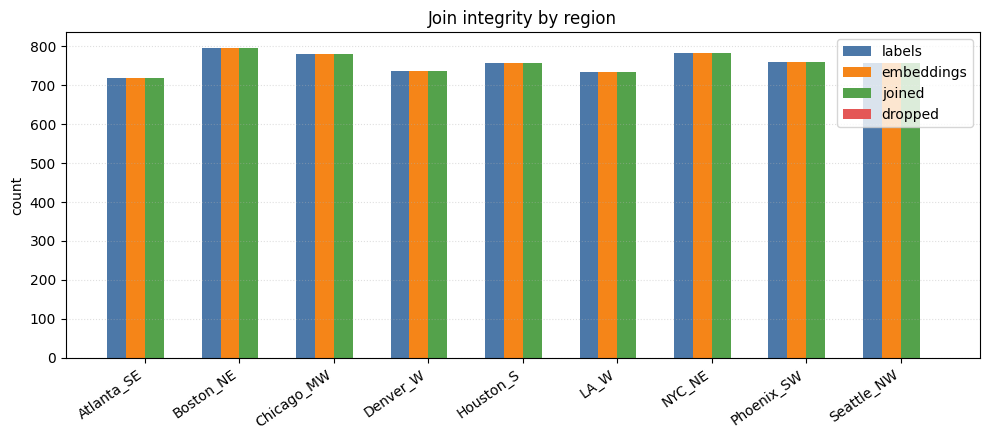

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(integrity))
w = 0.2
ax.bar(x - 1.5 * w, integrity["n_labels"], width=w, label="labels", color="#4C78A8")
ax.bar(x - 0.5 * w, integrity["n_embeddings"], width=w, label="embeddings", color="#F58518")
ax.bar(x + 0.5 * w, integrity["n_joined"], width=w, label="joined", color="#54A24B")
ax.bar(x + 1.5 * w, integrity["n_dropped"], width=w, label="dropped", color="#E45756")
ax.set_xticks(x)
ax.set_xticklabels(integrity["region"], rotation=35, ha="right")
ax.set_ylabel("count")
ax.set_title("Join integrity by region")
ax.legend(frameon=True)
ax.grid(True, axis="y", linestyle=":", alpha=0.4)
fig.tight_layout()
bar_path = OUT_DIR / "qa_join_integrity_bars.png"
fig.savefig(bar_path, dpi=150)
print("Saved", bar_path)
plt.show()


**Result.** Bars show labels = embeddings = joined for every city, with **0 dropped**. Visually confirms a clean join across all 9 metros.

### 4c. Shared-pixel collision map


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_shared_pixel_map.png
Collision pixels in Boston_NE: 0


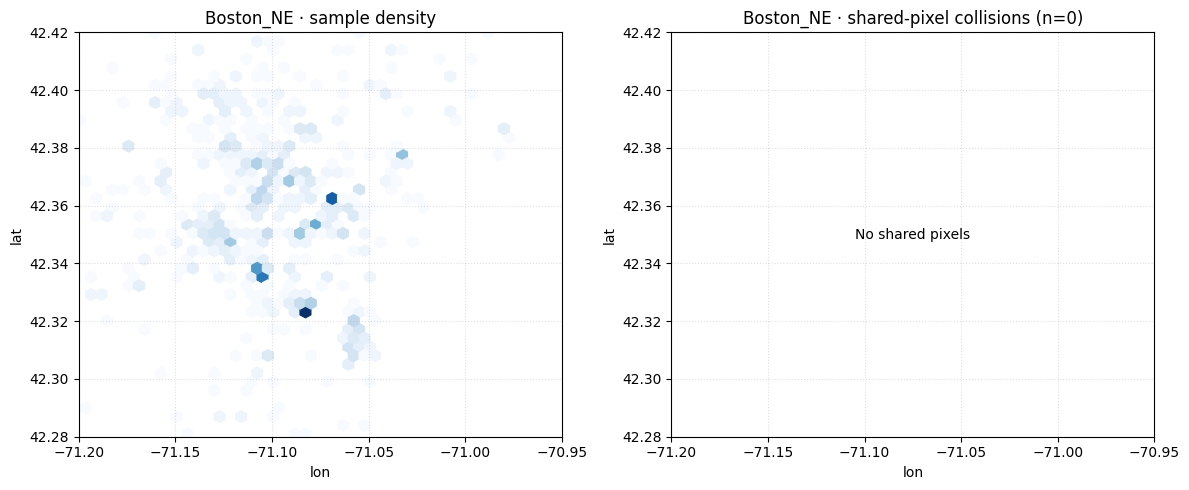

In [8]:
# Collision map for one example metro
region = "Boston_NE"
sub = gt[gt["region"] == region].copy()
sub["lon_r"] = sub["lon"].round(PIXEL_DECIMALS)
sub["lat_r"] = sub["lat"].round(PIXEL_DECIMALS)
coll = (
    sub.groupby(["lon_r", "lat_r"])
    .agg(n=("id", "size"), n_labels=("label", "nunique"))
    .reset_index()
)
coll_multi = coll[coll["n"] > 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hexbin(sub["lon"], sub["lat"], gridsize=40, cmap="Blues", mincnt=1)
axes[0].set_title(f"{region} · sample density")
axes[0].set_xlabel("lon")
axes[0].set_ylabel("lat")

if not coll_multi.empty:
    sc = axes[1].scatter(
        coll_multi["lon_r"],
        coll_multi["lat_r"],
        c=coll_multi["n_labels"],
        s=30 + 20 * coll_multi["n"],
        cmap="coolwarm",
        vmin=1,
        vmax=max(2, int(coll_multi["n_labels"].max())),
        edgecolors="k",
        linewidths=0.3,
    )
    cbar = fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
    cbar.set_label("# distinct labels in pixel")
else:
    axes[1].text(0.5, 0.5, "No shared pixels", ha="center", va="center", transform=axes[1].transAxes)
axes[1].set_title(f"{region} · shared-pixel collisions (n={len(coll_multi)})")
axes[1].set_xlabel("lon")
axes[1].set_ylabel("lat")

for ax in axes:
    xmin, ymin, xmax, ymax = US_REGIONS[region]
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.grid(True, linestyle=":", alpha=0.4)

fig.tight_layout()
shared_path = OUT_DIR / "qa_shared_pixel_map.png"
fig.savefig(shared_path, dpi=150)
print("Saved", shared_path)
print(f"Collision pixels in {region}: {len(coll_multi)}")
plt.show()


**Result.** In Boston, **0** buildings share the same ~10 m embedding pixel. No collision artifacts in this AOI — each sample gets its own embedding.

### 4d. Geographic NN vs embedding NN

For random anchors: geographic nearest neighbor should often have high cosine similarity
if embeddings are spatially coherent with the sample points.


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_nn_check.csv
Geo-NN mean cosine: 0.870 · Emb-NN mean distance m: 3609.8 · Emb-NN == Geo-NN rate: 0.10
Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_nn_geo_vs_embedding.png


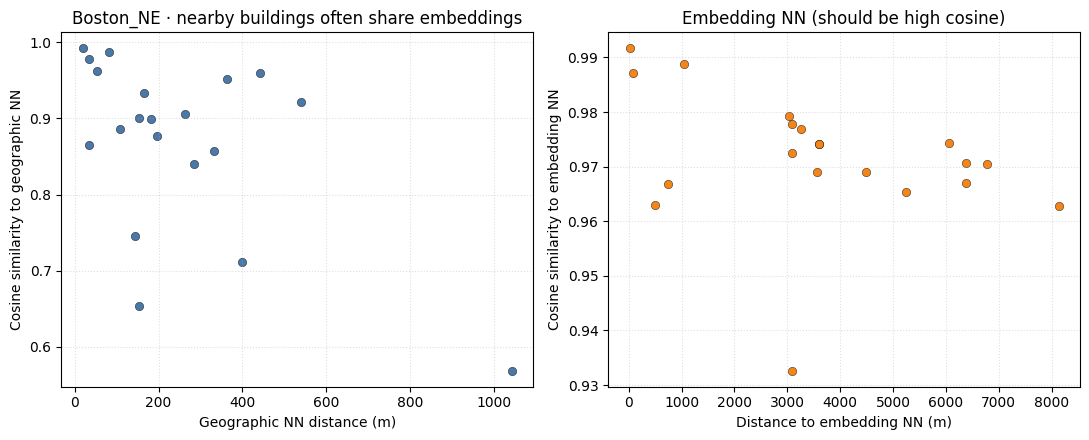

,label,geo_nn_label,geo_nn_m,geo_nn_cos,emb_nn_label,emb_nn_m,emb_nn_cos,same_as_geo
0,education,education,153.280,0.654,education,3602.236,0.974,False
1,commercial_office,terrace_ambiguous,143.224,0.745,commercial_office,3553.601,0.969,False
2,terrace_ambiguous,multi_family,19.225,0.992,multi_family,19.225,0.992,True
3,residential_generic,hospital,1041.893,0.569,terrace_ambiguous,6375.996,0.971,False
4,education,education,53.476,0.962,education,6381.918,0.967,False
5,education,education,34.889,0.978,single_family_like,3023.860,0.979,False
6,terrace_ambiguous,education,539.312,0.921,hospital,3096.985,0.978,False
7,hospital,hospital,362.661,0.952,hospital,752.168,0.967,False
8,commercial_office,terrace_ambiguous,285.011,0.840,multi_family,5239.080,0.965,False
9,industrial,industrial,165.123,0.933,terrace_ambiguous,6057.231,0.974,False


In [9]:
# Geographic NN vs embedding cosine NN for ~20 random buildings in one metro
rng = np.random.default_rng(RANDOM_STATE)
region = "Boston_NE"
sub = gt[gt["region"] == region].reset_index(drop=True)
assert len(sub) >= 30, f"Need more GT rows in {region} for NN check"

idx = rng.choice(len(sub), size=min(20, len(sub)), replace=False)
coords = sub[["lon", "lat"]].to_numpy(dtype=np.float64)
X = sub[BANDS].to_numpy(dtype=np.float64)
# L2-normalize for cosine
X_n = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)

nn_rows = []
for i in idx:
    # geographic distances (approx degrees → meters via local scale)
    dlon = (coords[:, 0] - coords[i, 0]) * np.cos(np.deg2rad(coords[i, 1]))
    dlat = coords[:, 1] - coords[i, 1]
    geo_m = np.hypot(dlon, dlat) * 111_320.0
    geo_m[i] = np.inf
    j_geo = int(np.argmin(geo_m))

    sims = X_n @ X_n[i]
    sims[i] = -np.inf
    j_emb = int(np.argmax(sims))

    nn_rows.append(
        {
            "id": sub.loc[i, "id"],
            "label": sub.loc[i, "label"],
            "lon": coords[i, 0],
            "lat": coords[i, 1],
            "geo_nn_id": sub.loc[j_geo, "id"],
            "geo_nn_label": sub.loc[j_geo, "label"],
            "geo_nn_m": float(geo_m[j_geo]),
            "geo_nn_cos": float(X_n[i] @ X_n[j_geo]),
            "emb_nn_id": sub.loc[j_emb, "id"],
            "emb_nn_label": sub.loc[j_emb, "label"],
            "emb_nn_m": float(geo_m[j_emb]) if np.isfinite(geo_m[j_emb]) else float("nan"),
            "emb_nn_cos": float(sims[j_emb]),
            "same_as_geo": j_geo == j_emb,
        }
    )

nn_df = pd.DataFrame(nn_rows)
nn_path = OUT_DIR / "qa_nn_check.csv"
nn_df.to_csv(nn_path, index=False)
print("Wrote", nn_path)
print(
    "Geo-NN mean cosine:",
    f"{nn_df['geo_nn_cos'].mean():.3f}",
    "· Emb-NN mean distance m:",
    f"{nn_df['emb_nn_m'].mean():.1f}",
    "· Emb-NN == Geo-NN rate:",
    f"{nn_df['same_as_geo'].mean():.2f}",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(nn_df["geo_nn_m"], nn_df["geo_nn_cos"], c="#4C78A8", edgecolors="k", linewidths=0.3)
axes[0].set_xlabel("Geographic NN distance (m)")
axes[0].set_ylabel("Cosine similarity to geographic NN")
axes[0].set_title(f"{region} · nearby buildings often share embeddings")
axes[0].grid(True, linestyle=":", alpha=0.4)

axes[1].scatter(nn_df["emb_nn_m"], nn_df["emb_nn_cos"], c="#F58518", edgecolors="k", linewidths=0.3)
axes[1].set_xlabel("Distance to embedding NN (m)")
axes[1].set_ylabel("Cosine similarity to embedding NN")
axes[1].set_title("Embedding NN (should be high cosine)")
axes[1].grid(True, linestyle=":", alpha=0.4)

fig.tight_layout()
nn_fig = OUT_DIR / "qa_nn_geo_vs_embedding.png"
fig.savefig(nn_fig, dpi=150)
print("Saved", nn_fig)
plt.show()
nn_df[["label", "geo_nn_label", "geo_nn_m", "geo_nn_cos", "emb_nn_label", "emb_nn_m", "emb_nn_cos", "same_as_geo"]]


**Result.** Nearby buildings are often similar in embedding space (geo-NN mean cosine **0.87**), but the *most* similar embedding is usually farther away (only **10%** match the geographic neighbor). So embeddings capture local structure, not just “closest building on the map.”

### 4e. AlphaEarth RGB context + GT overlay (requires EE)

False-color composite of bands `A01`, `A16`, `A32` with GT centroids overlaid on the
same annual mosaic used for sampling.


Earth Engine initialized · project = ee-kedarvaidya0504
Thumb URL fetched
Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/qa_embedding_rgb_overlay.png · overlay points = 36


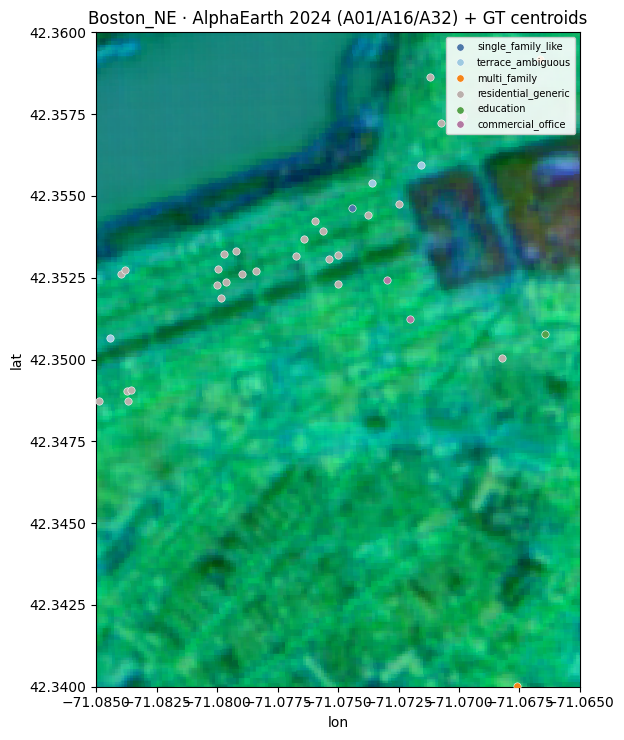

In [10]:
# False-color AlphaEarth mosaic + GT centroids for one zoomed neighborhood
init_ee(EE_PROJECT)
img = annual_embedding_image(EMBED_YEAR)
viz_region = "Boston_NE"
# zoom box ~0.02° near AOI center
cx, cy = region_centroid(US_REGIONS[viz_region])
half = 0.01
zoom = (cx - half, cy - half, cx + half, cy + half)
zxmin, zymin, zxmax, zymax = zoom

rgb = img.select(["A01", "A16", "A32"]).visualize(
    min=-0.3,
    max=0.3,
)
region_geom = ee.Geometry.Rectangle([zxmin, zymin, zxmax, zymax])
thumb_url = rgb.getThumbURL(
    {
        "region": region_geom,
        "dimensions": 512,
        "format": "png",
    }
)
print("Thumb URL fetched")

with urlreq.urlopen(thumb_url, timeout=120) as resp:
    thumb = np.array(Image.open(io.BytesIO(resp.read())))

pts = gt[
    (gt["region"] == viz_region)
    & (gt["lon"].between(zxmin, zxmax))
    & (gt["lat"].between(zymin, zymax))
]

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(thumb, extent=[zxmin, zxmax, zymin, zymax], origin="upper")
for lab, color in label_colors.items():
    p = pts[pts["label"] == lab]
    if p.empty:
        continue
    ax.scatter(
        p["lon"],
        p["lat"],
        s=28,
        c=color,
        label=lab,
        edgecolors="white",
        linewidths=0.4,
        zorder=3,
    )
ax.set_xlim(zxmin, zxmax)
ax.set_ylim(zymin, zymax)
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title(f"{viz_region} · AlphaEarth {EMBED_YEAR} (A01/A16/A32) + GT centroids")
ax.legend(loc="upper right", fontsize=7, framealpha=0.9)
ax.set_aspect(1.0 / np.cos(np.deg2rad(cy)))
fig.tight_layout()
rgb_path = OUT_DIR / "qa_embedding_rgb_overlay.png"
fig.savefig(rgb_path, dpi=150)
print("Saved", rgb_path, "· overlay points =", len(pts))
plt.show()


**Result.** False-color AlphaEarth thumbnail with 36 GT points overlaid. Confirms labels sit on real embedding pixels in the neighborhood, not empty/wrong locations.

### 4f. Cache reproducibility spot-check (requires EE)


In [11]:
# Spot-check: re-extract a tiny batch and compare to cache (cosine ≈ 1)
init_ee(EE_PROJECT)
spot = gt.sample(n=min(8, len(gt)), random_state=RANDOM_STATE).reset_index(drop=True)
fresh = extract_embeddings(spot[["id", "region", "lon", "lat"]], year=EMBED_YEAR, batch_size=8)
fresh = fresh.dropna(subset=BANDS)
merged = spot[["id"] + BANDS].merge(fresh[["id"] + BANDS], on="id", suffixes=("_cached", "_fresh"))
assert len(merged) > 0, "Spot-check produced no overlapping ids"

cosines = []
for _, r in merged.iterrows():
    a = r[[f"{b}_cached" for b in BANDS]].to_numpy(dtype=np.float64)
    b = r[[f"{b}_fresh" for b in BANDS]].to_numpy(dtype=np.float64)
    cosines.append(float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)))

print("Spot-check cosine(cached, fresh):", [round(c, 6) for c in cosines])
assert min(cosines) > 0.999, f"Cache mismatch: min cosine={min(cosines)}"
print("OK · cached embeddings match re-extract")


Earth Engine initialized · project = ee-kedarvaidya0504
Earth Engine initialized · project = ee-kedarvaidya0504
EE reduceRegions · 0:8 / 8
Spot-check cosine(cached, fresh): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
OK · cached embeddings match re-extract


**Result.** Cached embeddings match a fresh EE pull (cosine = 1.0 for all 8 spot-checks). The parquet cache is trustworthy to reuse.

## 5. Schema & snapshot

**`building_gt.parquet` columns**

- ids / geo: `id`, `region`, `lon`, `lat`
- raw GT: `subtype`, `class`
- study label: `label`
- sampling meta: `embed_year`, `sample_method`
- features: `A00` … `A63`

**Next.** Exploratory embedding analysis (PCA / UMAP / distances) and multi-class
classifiers in a follow-on notebook. Optional upgrades: footprint-mean pooling,
50 m / 200 m context buffers, Places joins for institutional recall.


In [12]:
snapshot = {
    "overture_release": RELEASE,
    "embedding_year": EMBED_YEAR,
    "sample_method": SAMPLE_METHOD,
    "n_labels": int(len(labels)),
    "n_embeddings": int(len(embeddings)),
    "n_gt": int(len(gt)),
    "n_per_class_target": N_PER_CLASS,
    "regions": list(US_REGIONS.keys()),
    "rollup": ROLLUP,
    "label_counts": gt["label"].value_counts().to_dict(),
    "shared_pixel_collisions": {
        "n_pixels": n_collision_pixels,
        "n_buildings": n_collision_buildings,
        "pixel_decimals": PIXEL_DECIMALS,
    },
    "join_integrity": integrity.to_dict(orient="records"),
    "outputs": sorted(p.name for p in OUT_DIR.iterdir()),
}
snap_path = OUT_DIR / "gt_snapshot.json"
snap_path.write_text(json.dumps(snapshot, indent=2))
print("Wrote", snap_path)
print(
    json.dumps(
        {
            "n_labels": snapshot["n_labels"],
            "n_embeddings": snapshot["n_embeddings"],
            "n_gt": snapshot["n_gt"],
            "label_counts": snapshot["label_counts"],
        },
        indent=2,
    )
)


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_gt/gt_snapshot.json
{
  "n_labels": 6822,
  "n_embeddings": 6822,
  "n_gt": 6822,
  "label_counts": {
    "single_family_like": 900,
    "multi_family": 900,
    "education": 900,
    "commercial_office": 900,
    "residential_generic": 900,
    "industrial": 884,
    "terrace_ambiguous": 835,
    "hospital": 603
  }
}


**Result.** Final GT table has **6,822** buildings with embeddings. Class counts are mostly balanced (~900 each); hospitals are scarcer (603). Dataset is ready for multi-class training.